In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor
import pickle
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded ✓")

Libraries loaded ✓


In [2]:
df = pd.read_csv('../data/train_ready.csv')
print(f"Shape: {df.shape}")

X = df.drop(columns=['price_clean'])
y = df['price_clean']

print(f"Features: {list(X.columns)}")
print(f"Target: price_clean")
print(f"\nPrice range: KSh {y.min():,.0f} → KSh {y.max():,.0f}")

Shape: (66, 7)
Features: ['bedrooms', 'bathrooms', 'floor_size_clean', 'price_per_sqm', 'location_encoded', 'type_encoded']
Target: price_clean

Price range: KSh 4,680,000 → KSh 127,100,000


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Train: {X_train.shape[0]} rows")
print(f"Test:  {X_test.shape[0]} rows")

Train: 52 rows
Test:  14 rows


In [4]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("=== Linear Regression (Baseline) ===")
print(f"RMSE: KSh {rmse_lr:,.0f}")
print(f"MAE:  KSh {mae_lr:,.0f}")
print(f"R²:   {r2_lr:.4f}")

=== Linear Regression (Baseline) ===
RMSE: KSh 5,896,170
MAE:  KSh 3,430,314
R²:   0.7249


In [5]:
xgb = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42,
    verbosity=0
)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)

rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)

print("=== XGBoost Regressor ===")
print(f"RMSE: KSh {rmse_xgb:,.0f}")
print(f"MAE:  KSh {mae_xgb:,.0f}")
print(f"R²:   {r2_xgb:.4f}")

=== XGBoost Regressor ===
RMSE: KSh 4,237,064
MAE:  KSh 2,607,559
R²:   0.8579



=== Model Comparison ===
Metric          Linear Reg         XGBoost
RMSE             5,896,170       4,237,064
MAE              3,430,314       2,607,559
R²                  0.7249          0.8579


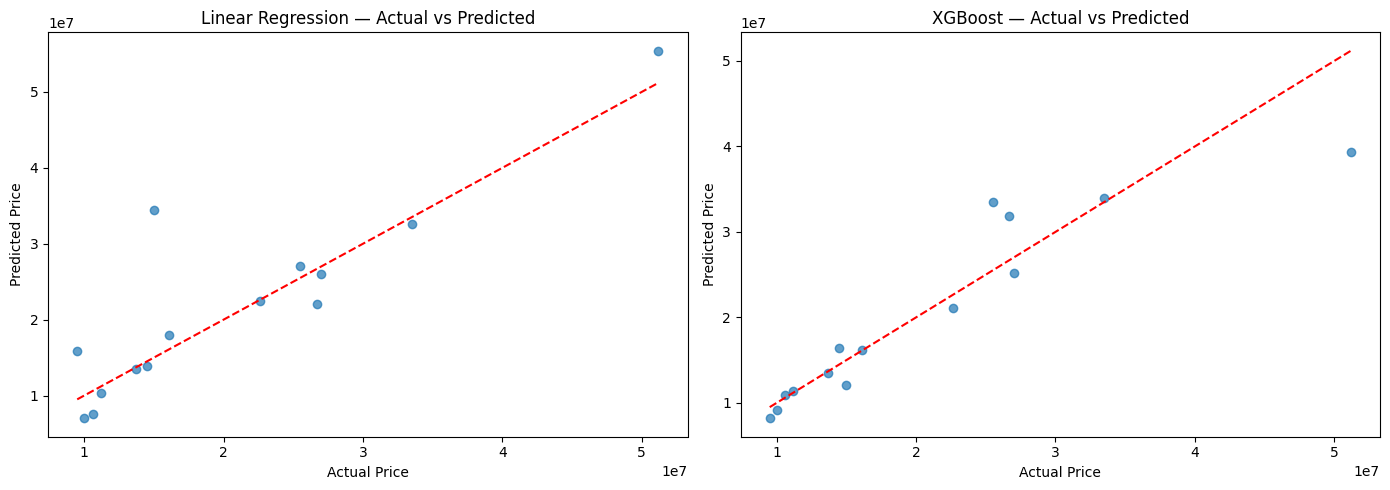

In [6]:
print("\n=== Model Comparison ===")
print(f"{'Metric':<10} {'Linear Reg':>15} {'XGBoost':>15}")
print(f"{'RMSE':<10} {rmse_lr:>15,.0f} {rmse_xgb:>15,.0f}")
print(f"{'MAE':<10} {mae_lr:>15,.0f} {mae_xgb:>15,.0f}")
print(f"{'R²':<10} {r2_lr:>15.4f} {r2_xgb:>15.4f}")

# Actual vs Predicted plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, preds, title in zip(axes, [y_pred_lr, y_pred_xgb], ['Linear Regression', 'XGBoost']):
    ax.scatter(y_test, preds, alpha=0.7)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
    ax.set_xlabel('Actual Price')
    ax.set_ylabel('Predicted Price')
    ax.set_title(f'{title} — Actual vs Predicted')

plt.tight_layout()
plt.savefig('../docs/model_comparison.png')
plt.show()

In [7]:
# Save XGBoost model
with open('../models/stage1_price_model.pkl', 'wb') as f:
    pickle.dump(xgb, f)

print("✅ Model saved to models/stage1_price_model.pkl")
print(f"\nBest model: XGBoost")
print(f"R²: {r2_xgb:.4f} — explains {r2_xgb*100:.1f}% of price variance")


✅ Model saved to models/stage1_price_model.pkl

Best model: XGBoost
R²: 0.8579 — explains 85.8% of price variance
